<a href="https://colab.research.google.com/github/Lukas98275/Mineria-de-datos/blob/main/Fifa19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Contexto del Conjunto de Datos (FIFA 19 Player Dataset):**
Este dataset contiene estadísticas detalladas de más de 18,000 jugadores del videojuego FIFA 19, extraídas de la base de datos oficial de EA Sports. Incluye más de 80 columnas que abarcan atributos físicos, habilidades técnicas (como pases, regates y tiros), datos demográficos y valoraciones económicas en el club.   Variable Objetivo Principal (Overall): Representa la valoración general de la habilidad actual del jugador en una escala numérica entera. Su análisis permite entender qué atributos influyen de manera más directa en el nivel competitivo general de un futbolista.Variable Objetivo Osecundaria (Value): Representa el valor de mercado actual del jugador. Presenta un fuerte sesgo hacia la derecha, por lo que requiere limpieza de formato (conversión de cadenas de texto con sufijos 'M' y 'K' a valores numéricos) y transformaciones logarítmicas para su correcta modelación predictiva.

In [3]:
from google.colab import files
archivos_subidos = files.upload()
nombre_csv = next(iter(archivos_subidos))
print("Archivo seleccionado:", nombre_csv)

Saving kl.csv to kl.csv
Archivo seleccionado: kl.csv


## 1. Carga de Datos y Análisis Exploratorio (EDA)
En esta sección cargamos el archivo de datos y realizamos la exploración visual de la distribución de la variable objetivo (`Overall`) mediante histogramas y diagramas de caja (box-plots), además de un mapa de calor para identificar visualmente qué variables guardan mayor correlación lineal con el objetivo.

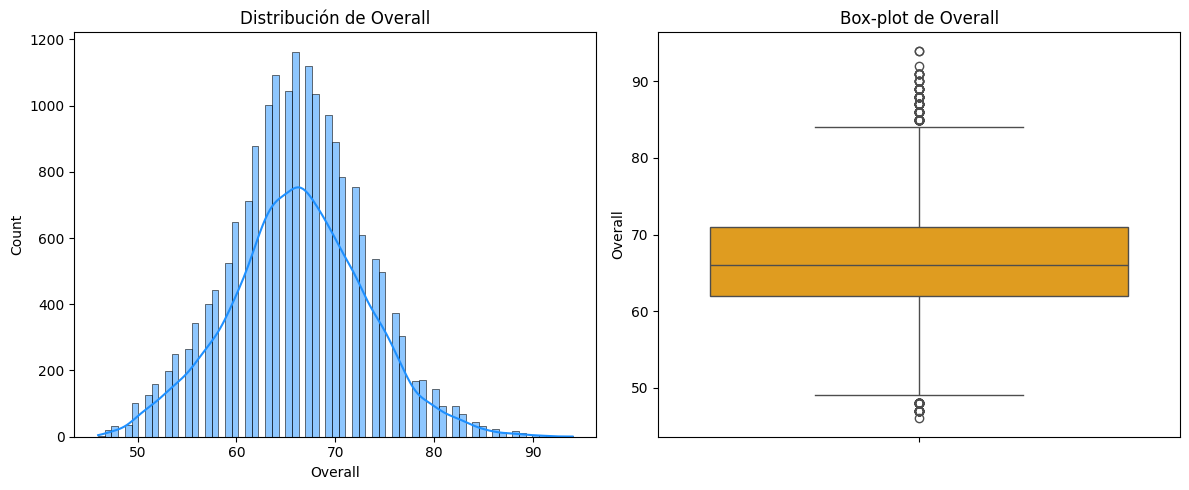

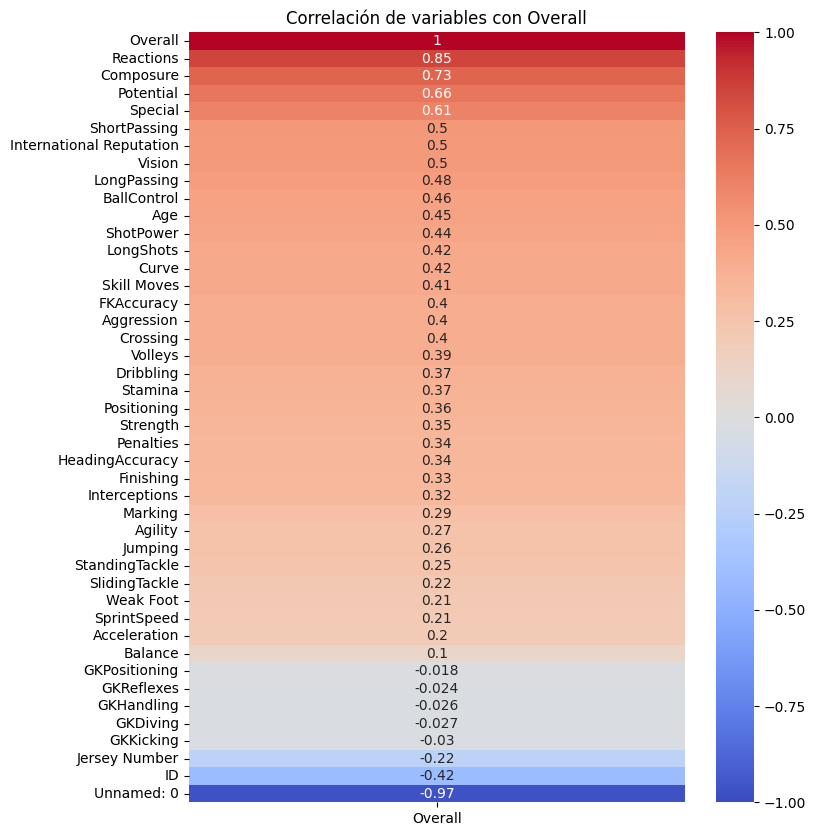

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset usando el nombre del archivo subido previamente con la codificación adecuada
df = pd.read_csv(nombre_csv, encoding='latin-1')

# 1. EDA de la variable objetivo 'Overall'
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Overall'], kde=True, color='dodgerblue')
plt.title('Distribución de Overall')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Overall'], color='orange')
plt.title('Box-plot de Overall')
plt.tight_layout()

plt.show()

# 2. Gráfico de correlaciones con Overall (solo variables numéricas)
plt.figure(figsize=(8, 10))
numeric_df = df.select_dtypes(include=['int64', 'float64'])
correlation = numeric_df.corr()[['Overall']].sort_values(by='Overall', ascending=False)
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación de variables con Overall')
plt.show()

In [10]:
# Seleccionamos 8 variables numéricas con alta correlación y sin data leakage directo
candidatas = [
    'Reactions',
    'Composure',
    'ShortPassing',
    'BallControl',
    'Vision',
    'LongPassing',
    'Stamina',
    'Agility'
]

# Filtrar datos limpios sin valores nulos en estas columnas
X = df[candidatas].dropna()
y = df.loc[X.index, 'Overall']


## 2. Selección de Predictores y Control de Data Leakage
Basándonos en la matriz de correlación, seleccionamos 8 variables candidatas.

* **Variables seleccionadas:** `Reactions`, `Composure`, `ShortPassing`, `BallControl`, `Vision`, `LongPassing`, `Stamina`, `Agility`.
* **Pregunta de control de Data Leakage:** ¿Esta variable contiene información sobre el futuro o sobre el resultado exacto que estamos intentando predecir de forma indirecta?
* **Descartes:** Se excluyó deliberadamente la variable `Potential`, ya que proyecta el crecimiento futuro del jugador y generaría una fuga de datos (data leakage) artificialmente alta sobre el rendimiento actual (`Overall`).

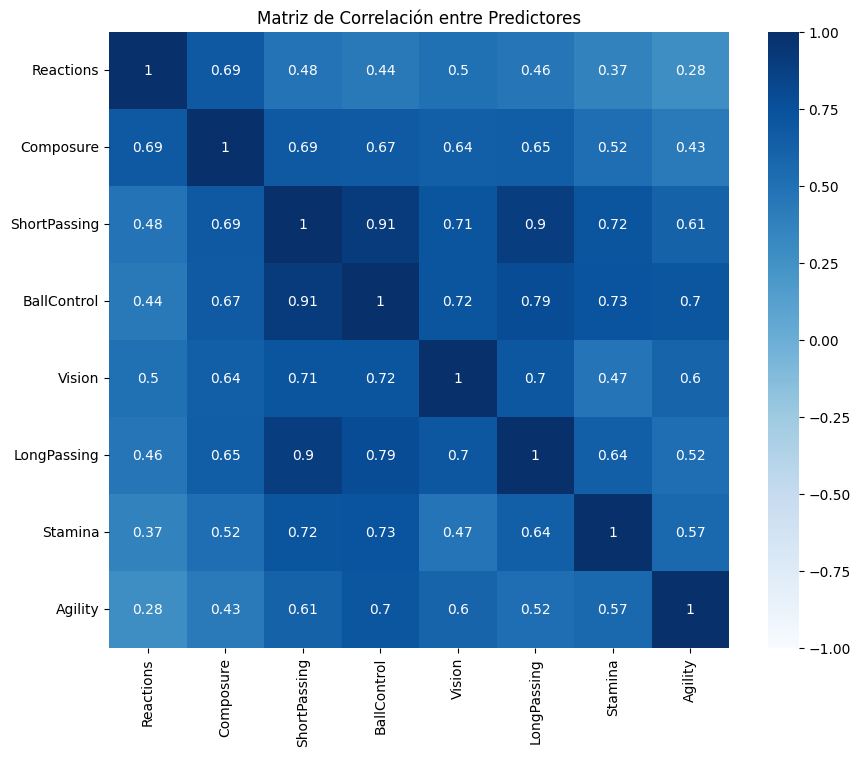

       Variable        VIF
0     Reactions   1.962393
1     Composure   2.932529
2  ShortPassing  11.931352
3   BallControl   8.368859
4        Vision   2.762426
5   LongPassing   5.549979
6       Stamina   2.367456
7       Agility   2.219321


In [11]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Matriz de correlación entre predictores
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap='Blues', vmin=-1, vmax=1)
plt.title('Matriz de Correlación entre Predictores')
plt.show()

# Cálculo del VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

print(vif_data)

## 3. Análisis de Multicolinealidad (VIF y Correlación)
Para evitar la redundancia entre variables independientes y asegurar la estabilidad de los coeficientes de la regresión lineal, evaluamos la matriz de correlación entre predictores y calculamos el Factor de Inflación de la Varianza (VIF) utilizando la librería `statsmodels`.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Aseguramos que eliminamos filas que tengan NaN tanto en los predictores (X) como en el target (y)
datos_completos = df[candidatas + ['Overall']].dropna()
X_clean = datos_completos[candidatas]
y_clean = datos_completos['Overall']

# Partición entrenamiento / prueba utilizando los datos limpios sin NaNs
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

# Entrenamiento
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Predicciones
y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)

# Reporte de métricas
print("--- CONJUNTO DE ENTRENAMIENTO ---")
print(f"R²: {r2_score(y_train, y_pred_train):.4f}")
print(f"MAE: {mean_absolute_error(y_train, y_pred_train):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}")

print("\n--- CONJUNTO DE PRUEBA ---")
print(f"R²: {r2_score(y_test, y_pred_test):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_test):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}")

# Coeficientes
coeficientes = pd.DataFrame({'Variable': X_clean.columns, 'Coeficiente': modelo.coef_})
print("\nCoeficientes:")
print(coeficientes)

--- CONJUNTO DE ENTRENAMIENTO ---
R²: 0.7655
MAE: 2.6290
RMSE: 3.3495

--- CONJUNTO DE PRUEBA ---
R²: 0.7607
MAE: 2.6565
RMSE: 3.3735

Coeficientes:
       Variable  Coeficiente
0     Reactions     0.505761
1     Composure     0.172520
2  ShortPassing     0.020721
3   BallControl    -0.017523
4        Vision     0.002220
5   LongPassing     0.010276
6       Stamina    -0.010823
7       Agility    -0.018739


## 4. Entrenamiento del Modelo y Evaluación de Métricas
Dividimos el conjunto de datos en entrenamiento (80%) y prueba (20%). Entrenamos el modelo de regresión múltiple y evaluamos su desempeño mediante las métricas $R^2$, MAE (Error Absoluto Medio) y RMSE (Raíz del Error Cuadrático Medio), interpretando los coeficientes de las variables más influyentes.

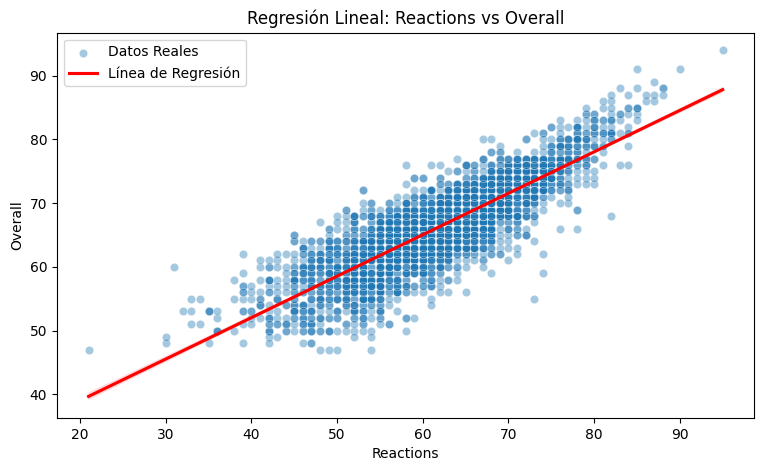

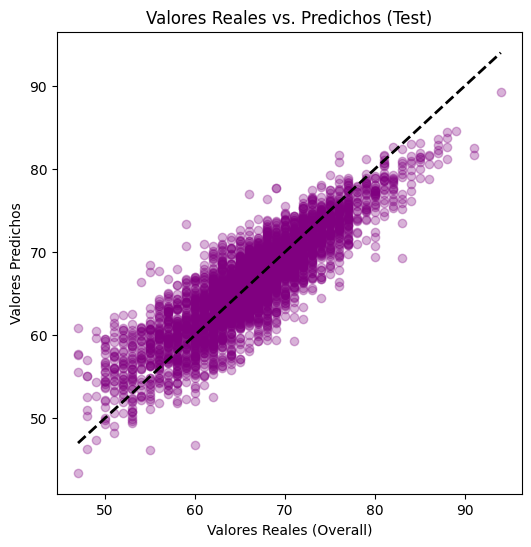

In [14]:
# 1. Gráfico del predictor más correlacionado vs Overall
best_predictor = 'Reactions'
plt.figure(figsize=(9, 5))
sns.scatterplot(x=X_test[best_predictor], y=y_test, alpha=0.4, label='Datos Reales')
sns.regplot(x=X_test[best_predictor], y=y_test, scatter=False, color='red', label='Línea de Regresión')
plt.title(f'Regresión Lineal: {best_predictor} vs Overall')
plt.legend()
plt.show()

# 2. Valores Reales vs Predichos
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_test, alpha=0.3, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.xlabel('Valores Reales (Overall)')
plt.ylabel('Valores Predichos')
plt.title('Valores Reales vs. Predichos (Test)')
plt.show()

## 5. Análisis de Heterogeneidad por Subgrupos
Evaluamos si el comportamiento del modelo varía dependiendo de la posición táctica del jugador (por ejemplo, separando entre jugadores de campo y defensas), calculando las métricas de error de forma independiente para cada subgrupo.

In [15]:
# Unir predicciones de test con la columna Position original
df_test = X_test.copy()
df_test['Overall_Real'] = y_test
df_test['Overall_Pred'] = y_pred_test
df_test['Position'] = df.loc[X_test.index, 'Position']

# Agrupar por posición general
def categorizar_posicion(pos):
    if pos in ['ST', 'CF', 'LW', 'RW', 'CAM', 'LM', 'RM', 'CM', 'CDM', 'LM']:
        return 'Jugador de Campo'
    elif pos in ['CB', 'LB', 'RB', 'LWB', 'RWB']:
        return 'Defensor'
    else:
        return 'Arquero/Otro'

df_test['Grupo'] = df_test['Position'].apply(categorizar_posicion)

# Evaluar métricas por cada subgrupo
for grupo, datos in df_test.groupby('Grupo'):
    if len(datos) > 5:
        r2 = r2_score(datos['Overall_Real'], datos['Overall_Pred'])
        rmse = np.sqrt(mean_squared_error(datos['Overall_Real'], datos['Overall_Pred']))
        print(f"Subgrupo: {grupo} (n={len(datos)}) -> R²: {r2:.4f}, RMSE: {rmse:.4f}")

Subgrupo: Arquero/Otro (n=1016) -> R²: 0.7555, RMSE: 3.4776
Subgrupo: Defensor (n=909) -> R²: 0.7932, RMSE: 3.0146
Subgrupo: Jugador de Campo (n=1707) -> R²: 0.7426, RMSE: 3.4896


## 6. Desafío Opcional: Predicción del Valor de Mercado (`Value`)
Limpiamos y transformamos la columna `Value` (convertido de texto con formato de moneda y sufijos K/M a un tipo de dato numérico continuo). Analizamos su distribución original y evaluamos el impacto de aplicar una transformación logarítmica para mejorar la estabilidad del modelo predictivo.

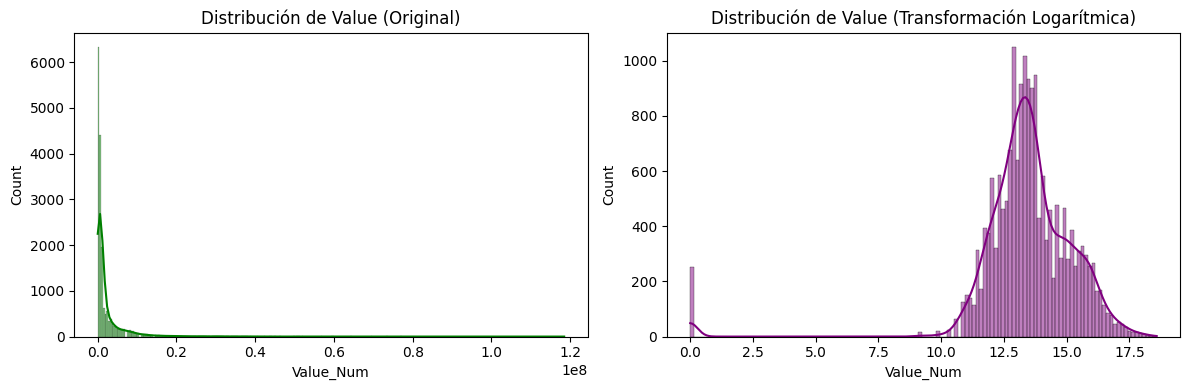

In [17]:
def limpiar_valor(val):
    if isinstance(val, str):
        # Reemplazar tanto el símbolo de euro físico como su representación en latin-1 (\x80)
        val = val.replace('€', '').replace('\x80', '')
        if 'M' in val:
            return float(val.replace('M', '')) * 1e6
        elif 'K' in val:
            return float(val.replace('K', '')) * 1e3
    try:
        return float(val)
    except ValueError:
        return None

# Aplicar limpieza
df['Value_Num'] = df['Value'].apply(limpiar_valor)

# Visualizar distribución original vs transformada con Log
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['Value_Num'].dropna(), kde=True, color='green')
plt.title('Distribución de Value (Original)')

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['Value_Num'].dropna()), kde=True, color='purple')
plt.title('Distribución de Value (Transformación Logarítmica)')
plt.tight_layout()
plt.show()